# Experiment 2: targeted training with TF-IDF

This notebook tests whether giving uncertain examples more weight improves the TF-IDF baseline. It uses the same preprocessing and logistic-regression setup as `01_baseline.ipynb`. The only added intervention is the `is_hard` margin feature and targeted sample weighting.

## Imports

In [1]:
import os
import pickle
import sys

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score

sys.path.append("..")
from utils.hard_samples_identify import add_is_hard
from utils.preprocessing import LABELS, clean_text, encode_labels


## Load and preprocess the data

In [2]:
train_df = pd.read_csv("../data/train.csv")
val_df = pd.read_csv("../data/val.csv")
test_df = pd.read_csv("../data/test.csv")

y_train = encode_labels(train_df.label)
y_val = encode_labels(val_df.label)
y_test = encode_labels(test_df.label)

vectorizer = TfidfVectorizer(
    preprocessor=clean_text,
    tokenizer=str.split,
    token_pattern=None,
    ngram_range=(1, 2),
    sublinear_tf=True,
)
X_train = vectorizer.fit_transform(train_df.sentence)
X_val = vectorizer.transform(val_df.sentence)
X_test = vectorizer.transform(test_df.sentence)

print(X_train.shape, X_val.shape, X_test.shape)


(2901, 39035) (967, 39035) (968, 39035)


## Train the baseline model

Accuracy: 0.7766287487073423
Macro F1: 0.7172412958027023
              precision    recall  f1-score   support

    negative       0.75      0.55      0.63       121
     neutral       0.81      0.89      0.85       574
    positive       0.71      0.64      0.67       272

    accuracy                           0.78       967
   macro avg       0.76      0.69      0.72       967
weighted avg       0.77      0.78      0.77       967



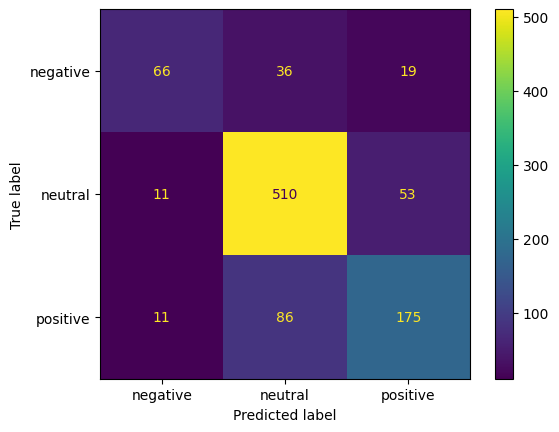

In [3]:
baseline_model = LogisticRegression(C=10, class_weight="balanced", max_iter=2000)
baseline_model.fit(X_train, y_train)

baseline_val_predictions = baseline_model.predict(X_val)
print("Accuracy:", accuracy_score(y_val, baseline_val_predictions))
print("Macro F1:", f1_score(y_val, baseline_val_predictions, average="macro"))
print(classification_report(y_val, baseline_val_predictions, target_names=LABELS))
ConfusionMatrixDisplay.from_predictions(
    y_val, baseline_val_predictions, display_labels=LABELS
)


## Add the `is_hard` feature

The margin is the difference between the two highest predicted probabilities. An example is hard when its margin is at most `0.2`. The baseline predictions define the feature for all three splits.

In [4]:
train_probabilities = baseline_model.predict_proba(X_train)
val_probabilities = baseline_model.predict_proba(X_val)
test_probabilities = baseline_model.predict_proba(X_test)

train_df = add_is_hard(train_df, train_probabilities, 0.2)
val_df = add_is_hard(val_df, val_probabilities, 0.2)
test_df = add_is_hard(test_df, test_probabilities, 0.2)

train_is_hard = train_df.is_hard.to_numpy()
val_is_hard = val_df.is_hard.to_numpy()
test_is_hard = test_df.is_hard.to_numpy()

print("Hard training examples:", train_is_hard.sum())
print("Hard validation examples:", val_is_hard.sum())
print("Hard test examples:", test_is_hard.sum())


Hard training examples: 5
Hard validation examples: 153
Hard test examples: 133


## Train the targeted model

Hard examples receive a sample weight of `3.0`; all other examples receive a weight of `1.0`. The targeted model uses the same TF-IDF features and logistic-regression hyperparameters as the baseline.

In [5]:
targeted_model = LogisticRegression(C=10, class_weight="balanced", max_iter=2000)
targeted_model.fit(
    X_train,
    y_train,
    sample_weight=np.where(train_is_hard, 3.0, 1.0),
)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,10
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


## Evaluate both models


Baseline
Overall accuracy: 0.7799586776859504
Overall macro F1: 0.7361905674427955
Hard accuracy: 0.5037593984962406
Hard macro F1: 0.46776267007138506
Easy accuracy: 0.8239520958083832
Easy macro F1: 0.7826311426535391
              precision    recall  f1-score   support

    negative       0.75      0.63      0.68       121
     neutral       0.82      0.87      0.84       575
    positive       0.71      0.66      0.68       272

    accuracy                           0.78       968
   macro avg       0.76      0.72      0.74       968
weighted avg       0.78      0.78      0.78       968

Hard negative: TP=6, FN=14
Hard neutral: TP=33, FN=29
Hard positive: TP=28, FN=23

Targeted
Overall accuracy: 0.7778925619834711
Overall macro F1: 0.7332402677904634
Hard accuracy: 0.48872180451127817
Hard macro F1: 0.44309759301950874
Easy accuracy: 0.8239520958083832
Easy macro F1: 0.7826311426535391
              precision    recall  f1-score   support

    negative       0.74      0.62      

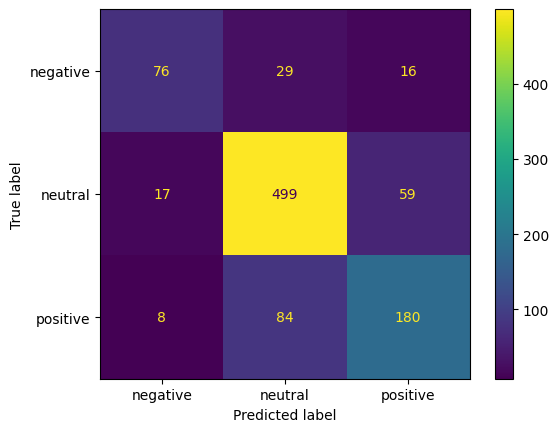

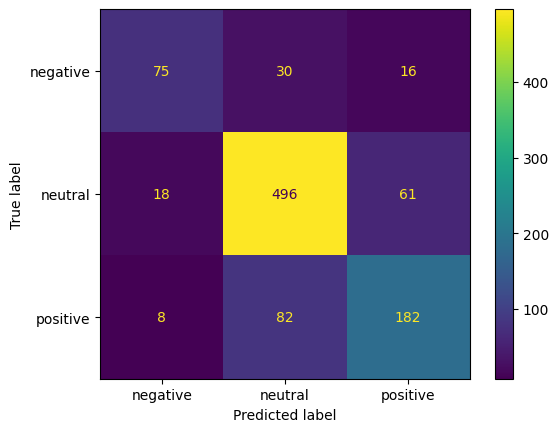

In [6]:
for model, name in [(baseline_model, "Baseline"), (targeted_model, "Targeted")]:
    probabilities = model.predict_proba(X_test)
    predictions = model.predict(X_test)
    hard_true = y_test[test_is_hard]
    hard_pred = predictions[test_is_hard]
    easy_true = y_test[~test_is_hard]
    easy_pred = predictions[~test_is_hard]

    print("\n" + name)
    print("Overall accuracy:", accuracy_score(y_test, predictions))
    print("Overall macro F1:", f1_score(y_test, predictions, average="macro"))
    print("Hard accuracy:", accuracy_score(hard_true, hard_pred))
    print("Hard macro F1:", f1_score(hard_true, hard_pred, average="macro"))
    print("Easy accuracy:", accuracy_score(easy_true, easy_pred))
    print("Easy macro F1:", f1_score(easy_true, easy_pred, average="macro"))
    print(classification_report(y_test, predictions, target_names=LABELS))
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=LABELS)

    for class_id, label in enumerate(LABELS):
        tp = ((hard_true == class_id) & (hard_pred == class_id)).sum()
        fn = ((hard_true == class_id) & (hard_pred != class_id)).sum()
        print(f"Hard {label}: TP={tp}, FN={fn}")


## Save the results

In [ ]:
# os.makedirs("../models", exist_ok=True)
# os.makedirs("../results/probs", exist_ok=True)

# train_df.to_csv("../results/experiment_2_train_with_hard.csv", index=False)
# val_df.to_csv("../results/experiment_2_val_with_hard.csv", index=False)
# test_df.to_csv("../results/experiment_2_test_with_hard.csv", index=False)

# with open("../models/targeted_tfidf_vectorizer.pkl", "wb") as f:
#     pickle.dump(vectorizer, f)
# with open("../models/targeted_logreg.pkl", "wb") as f:
#     pickle.dump(targeted_model, f)

# def save_probabilities(model, data, X, labels, name):
#     probabilities = model.predict_proba(X)
#     predictions = model.predict(X)
#     output = data[["sentence", "label", "is_hard"]].copy()
#     output[["p_negative", "p_neutral", "p_positive"]] = probabilities
#     output["p_true"] = probabilities[np.arange(len(data)), labels]
#     output["pred"] = [LABELS[i] for i in predictions]
#     output.to_csv(f"../results/probs/{name}_test.csv", index=False)

# save_probabilities(baseline_model, test_df, X_test, y_test, "experiment_2_baseline_tfidf")
# save_probabilities(targeted_model, test_df, X_test, y_test, "experiment_2_targeted_tfidf")
